# AdaBoost
### A walkthrough of `AdaBoost.py` and `DecisionTreeAdaBoost.py`

**AdaBoost** (adaptive boosting) builds a strong classifier from many *weak* ones, typically decision stumps (trees with a single split), each only slightly better than guessing. It trains them **one after another**. After each round it raises the weight of the training samples the current learner got wrong, so the next learner is forced to concentrate on them. The final prediction is a **weighted vote**, in which more accurate learners get a larger say.

This notebook derives AdaBoost from first principles and runs the implementation in this folder at every step. By the end you should be able to:

1. explain what "boosting" means and why it reduces **bias**, in contrast with bagging, which reduces variance;
2. derive AdaBoost's learner weight $\alpha = \frac12\ln\frac{1-\varepsilon}{\varepsilon}$ and its re-weighting rule as greedy minimisation of the **exponential loss**, and extend them to $K$ classes (**SAMME**);
3. show that the repo's update, written in the symmetric binary form, is *exactly* SAMME;
4. explain how the weighted stump in `DecisionTreeAdaBoost.py` uses sample weights in its impurity, gain and leaf values;
5. trace three rounds of boosting by hand, and predict the effects of `n_estimators`, `learning_rate` and `max_depth`, including AdaBoost's sensitivity to label noise.

The tree code builds on the [Decision Tree walkthrough](../DecisionTree/DecisionTree_Walkthrough.ipynb). The contrast with bagging refers to the [Random Forest walkthrough](../RandomForest/RandomForest_Walkthrough.ipynb).

**Pattern.** Each core topic follows **Concept → Math → Illustration → Your implementation → Check**. Cells titled *🔧 Fixed in the code* record bugs found while this notebook was being written and since corrected in the `.py` files. Each gives the original behaviour, the fix, and a demonstration. Cells titled *⚠️ Note on the implementation* describe design choices that remain.

**Series:** [Decision Tree](../DecisionTree/DecisionTree_Walkthrough.ipynb) · [Regression Tree](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) · [Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb) · **AdaBoost** · [Gradient Boosting (regression)](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) · [Gradient Boosting (classification)](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb) · [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)

**Notation.** $n$ samples, $m$ features, $K$ classes; $T$ boosting rounds (`n_estimators`); $h_t$ is the weak learner of round $t$. $w_i^{(t)}$ is the weight of sample $i$ when $h_t$ is trained (normalised so that $\sum_i w_i^{(t)} = 1$). $\varepsilon_t$ is the weighted error of $h_t$, $\alpha_t$ its vote weight, and $\eta$ the learning rate. For binary derivations, labels are coded $y_i \in \{-1, +1\}$ and the ensemble score is $F_T(x) = \sum_t \alpha_t h_t(x)$.

## 1. Setup

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "AdaBoost.py").exists(), "Open/run this notebook from inside the AdaBoost/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from this folder, never copied into the notebook
from AdaBoost import AdaBoostClassifier
from DecisionTreeAdaBoost import DecisionTreeClassifier as WeightedTree

print("AdaBoostClassifier methods:", [k for k in vars(AdaBoostClassifier) if not k.startswith("__")])
print("weighted tree methods:     ", [k for k in vars(WeightedTree) if not k.startswith("__")])

AdaBoostClassifier methods: ['fit', 'predict', 'get_staged_predictions', 'get_estimator_weights', 'get_estimator_errors']
weighted tree methods:      ['build_tree', 'get_best_split', 'information_gain', 'split', 'entropy', 'gini_index', 'calculate_leaf_value', 'print_tree', 'fit', 'predict', 'make_prediction']


## 2. The problem: turning weak rules into a strong classifier

The task is supervised classification: learn $\hat f: \mathbb{R}^m \to \{0, \dots, K-1\}$ with small misclassification risk. Boosting starts from a different question. In 1988, Kearns and Valiant asked whether a "weak" learner that is only slightly better than random guessing can always be turned into a "strong" learner that is arbitrarily accurate. AdaBoost (Freund & Schapire, 1995–97) answered *yes* constructively.

The canonical weak learner is a **decision stump**, a single threshold on a single feature. On its own a stump is a terrible model for anything but the simplest boundary. The cell below shows a stump on the noisy "moons" data.

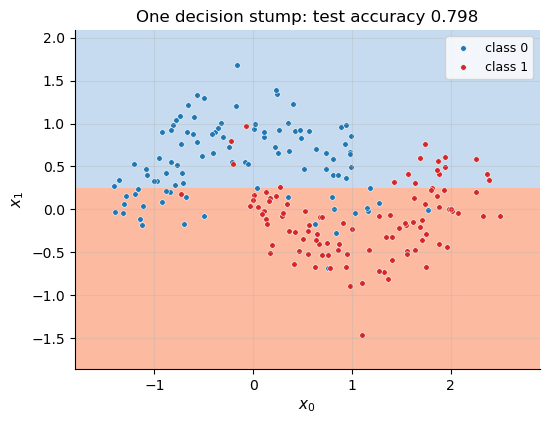

X_1 <= 0.23111485067113338 ? 0.16324992463069027
    left:1.0
    right:0.0


In [4]:
X_tr, y_tr = make_moons(200, noise=0.25)
X_te, y_te = make_moons(1000, noise=0.25)
stump = WeightedTree(max_depth=1); stump.fit(X_tr, y_tr)                       # uniform weights by default
acc = lambda pred, y: np.mean(np.asarray(pred) == y)
fig, ax = plt.subplots(figsize=(6, 4.4))
plot_decision_regions(stump.predict, X_tr, y_tr, ax=ax, title=f"One decision stump: test accuracy {acc(stump.predict(X_te), y_te):.3f}")
plt.show()
stump.print_tree()

One straight cut parallel to an axis cannot follow the curved boundary between the moons. The stump has high **bias**: it is too simple. Its variance is low, since another training set would give almost the same cut. Averaging many such stumps, as a random forest would, cannot fix that; the [Random Forest notebook](../RandomForest/RandomForest_Walkthrough.ipynb) shows that voting removes variance, not bias. We need to *combine stumps so that they complement each other*.

## 3. Why boosting fits this problem

**The idea.** Train learners *sequentially*. After each round, look at which samples the ensemble still gets wrong and increase their importance (weight), so that the next weak learner, which minimises *weighted* error, is pulled toward exactly those samples. Each new stump therefore covers a weakness of the ensemble so far. The ensemble prediction is a weighted vote

$$
\hat f(x) = \arg\max_k \sum_{t=1}^{T} \alpha_t\, \mathbb{1}[h_t(x) = k],
$$

so a sum of many simple rules can draw a complex boundary.

**Bias, not variance.** A sum of $T$ stumps is an *additive model* that is far more flexible than one stump, so boosting mainly **reduces bias**. Because each learner depends on the previous ones, boosting can also overfit if it runs too long. This is the mirror image of bagging, which keeps the flexible trees' low bias and reduces their variance by averaging independent copies.

**Strengths.** Very effective with tiny weak learners; few hyperparameters; a clean theory (exponential loss, margins, a training-error bound).
**Weaknesses.** Sequential, so it cannot be parallelised across rounds. Sensitive to **label noise and outliers**, because mislabelled points keep getting heavier (§7.4). No calibrated probabilities.

## 4. Core concepts, theory and math

### 4.1 Weak learners that respect sample weights

**Concept.** AdaBoost needs a learner that minimises *weighted* error: a sample with weight $0.2$ should count as much as twenty samples of weight $0.01$. `DecisionTreeAdaBoost.DecisionTreeClassifier` is the CART classifier with every count replaced by a sum of weights.

**Math.** For a node $S$ with weights $w_i$, let $W(S) = \sum_{i\in S} w_i$ and define the **weighted class proportions**

$$
p_k^w(S) = \frac{\sum_{i\in S,\, y_i = k} w_i}{W(S)} .
$$

Then:
- weighted Gini: $G^w(S) = 1 - \sum_k p_k^w(S)^2$;
- weighted gain: $\Delta^w = G^w(S) - \frac{W(S_L)}{W(S)} G^w(S_L) - \frac{W(S_R)}{W(S)} G^w(S_R)$, with children weighted by their share of the total *weight*, not their sample count;
- leaf value: $v = \arg\max_k \sum_{i \in S_\ell,\, y_i = k} w_i$, the weighted majority, which minimises the leaf's weighted error.

With uniform weights all three reduce to the unweighted versions in the [Decision Tree notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb).

**Illustration.** Re-weighting can change which split is best. In the 1-D example below, the point at $x = 7$ is a class-0 point sitting among class-1 points. With uniform weights the stump simply gets it wrong. Once that point carries a large weight, the stump moves to get it right.

In [5]:
x1d = np.arange(1, 11, dtype=float).reshape(-1, 1)
y1d = np.array([0, 0, 0, 0, 0, 1, 0, 1, 1, 1], dtype=float)          # point at x=7 is a class-0 point among class-1
w_uniform = np.full(10, 0.1)
w_heavy = w_uniform.copy(); w_heavy[6] = 0.6; w_heavy /= w_heavy.sum()   # emphasise sample 6 (x=7)
for name, w in [("uniform weights", w_uniform), ("sample 6 (x=7) up-weighted", w_heavy)]:
    t = WeightedTree(max_depth=1); t.fit(x1d, y1d, w)
    print(f"{name:<28}: stump x_0 <= {t.root.threshold}, leaves {t.root.left.value}/{t.root.right.value}, "
          f"weighted error {np.sum(w * (np.array(t.predict(x1d)) != y1d)) / w.sum():.3f}")

uniform weights             : stump x_0 <= 5.0, leaves 0.0/1.0, weighted error 0.100
sample 6 (x=7) up-weighted  : stump x_0 <= 7.0, leaves 0.0/1.0, weighted error 0.067


With uniform weights the best stump is $x_0 \le 5$, which misclassifies only the class-0 point at $x = 7$. Once that point carries 40% of the total weight, misclassifying it costs more than anything else, so the weighted learner chooses a different cut that gets it right and sacrifices cheaper points instead. This is the mechanism AdaBoost exploits: **the weights steer the next learner**.

**Your implementation and check.** `gini_index(y, weights)`, `information_gain(...)` and `calculate_leaf_value(y, weights)` against the weighted formulas.

In [6]:
wt = WeightedTree()
def gini_w(y, w):                         # Illustration only — weighted Gini formula
    p = np.array([w[y == k].sum() for k in np.unique(y)]) / w.sum()
    return 1 - np.sum(p**2)
for _ in range(300):
    n_ = int(rng.integers(2, 25)); y_ = rng.integers(0, 3, n_).astype(float); w_ = rng.random(n_); s = int(rng.integers(1, n_))
    assert np.isclose(wt.gini_index(y_, w_), gini_w(y_, w_))
    gain = gini_w(y_, w_) - (w_[:s].sum() * gini_w(y_[:s], w_[:s]) + w_[s:].sum() * gini_w(y_[s:], w_[s:])) / w_.sum()
    assert np.isclose(wt.information_gain(y_, y_[:s], y_[s:], w_, w_[:s], w_[s:], "gini"), gain)
    best = max(np.unique(y_), key=lambda k: w_[y_ == k].sum())
    assert wt.calculate_leaf_value(y_, w_) == best
print("✓ weighted gini_index, information_gain and calculate_leaf_value match the weighted formulas (300 random cases)")

✓ weighted gini_index, information_gain and calculate_leaf_value match the weighted formulas (300 random cases)


All three weighted building blocks match the formulas, so the tree minimises exactly the weighted criteria AdaBoost needs.

### 4.2 AdaBoost as greedy minimisation of the exponential loss (binary case)

**Concept.** AdaBoost was invented as an algorithm, but it can be *derived* from one principle (Friedman, Hastie & Tibshirani, 2000): build an additive model $F(x) = \sum_t \alpha_t h_t(x)$ one term at a time, each time adding the term that most reduces the **exponential loss**

$$
L(F) = \sum_{i=1}^{n} \exp\big(-y_i F(x_i)\big), \qquad y_i \in \{-1, +1\}. \tag{1}
$$

The product $y_i F(x_i)$ is the **margin**: positive when the sign of $F$ is right, and large when the ensemble is confident. The exponential loss is a smooth upper bound on the 0–1 loss, $\mathbb{1}[y F(x) \le 0] \le e^{-yF(x)}$.

**Math.** Suppose $F_{t-1}$ is fixed, and we add $\alpha\, h(x)$ with $h(x) \in \{-1, +1\}$. Then

$$
L(F_{t-1} + \alpha h) = \sum_i \underbrace{e^{-y_i F_{t-1}(x_i)}}_{=:\, \tilde w_i}\; e^{-\alpha y_i h(x_i)} .
$$

The factor $\tilde w_i$ does not depend on the new term: it is exactly the **sample weight**, large for points the current ensemble gets wrong. Normalise $w_i = \tilde w_i / \sum_j \tilde w_j$. Since $y_i h(x_i) = +1$ for correct and $-1$ for wrong predictions,

$$
\frac{L}{\sum_j \tilde w_j} = e^{-\alpha}\!\!\sum_{i:\,h(x_i) = y_i}\!\! w_i + e^{\alpha}\!\!\sum_{i:\,h(x_i) \ne y_i}\!\! w_i = e^{-\alpha}(1-\varepsilon) + e^{\alpha}\varepsilon, \qquad \varepsilon = \sum_{i:\, h(x_i)\ne y_i} w_i . \tag{2}
$$

*Step 1, choosing $h$.* For any fixed $\alpha > 0$, Eq. (2) equals $e^{-\alpha} + (e^{\alpha} - e^{-\alpha})\varepsilon$, which is increasing in $\varepsilon$. So the best weak learner is the one with the **smallest weighted error**, which is what the weighted tree tries to find.

*Step 2, choosing $\alpha$.* Differentiate Eq. (2) and set the derivative to zero:

$$
-e^{-\alpha}(1-\varepsilon) + e^{\alpha}\varepsilon = 0 \;\Longrightarrow\; e^{2\alpha} = \frac{1-\varepsilon}{\varepsilon} \;\Longrightarrow\; \alpha^* = \frac12 \ln\frac{1-\varepsilon}{\varepsilon}. \tag{3}
$$

The second derivative $e^{-\alpha}(1-\varepsilon) + e^{\alpha}\varepsilon > 0$, so this is the minimum. Note that $\alpha^* > 0$ exactly when $\varepsilon < \tfrac12$: a learner is useful when it beats a coin flip.

*Step 3, the new weights.* $\tilde w_i^{(t+1)} = e^{-y_i F_t(x_i)} = \tilde w_i^{(t)}\, e^{-\alpha_t y_i h_t(x_i)}$, so

$$
w_i^{(t+1)} \propto w_i^{(t)} \times \begin{cases} e^{+\alpha_t} & \text{if } h_t \text{ misclassifies } x_i,\\ e^{-\alpha_t} & \text{if } h_t \text{ classifies it correctly.}\end{cases} \tag{4}
$$

*Step 4, the minimum value.* Substituting $\alpha^*$ into Eq. (2) gives $Z_t = 2\sqrt{\varepsilon_t(1-\varepsilon_t)}$, the factor by which the (normalised) exponential loss shrinks in round $t$. Since the 0–1 loss is bounded by the exponential loss, the **training error** after $T$ rounds satisfies

$$
\frac1n\sum_i \mathbb{1}[\operatorname{sign} F_T(x_i) \ne y_i] \;\le\; \frac1n\sum_i e^{-y_i F_T(x_i)} \;=\; \prod_{t=1}^{T} 2\sqrt{\varepsilon_t(1-\varepsilon_t)} . \tag{5}
$$

Each factor is below 1 whenever $\varepsilon_t < \tfrac12$. Writing $\varepsilon_t = \tfrac12 - \gamma_t$, the product is at most $\exp(-2\sum_t\gamma_t^2)$, so training error falls **exponentially fast** as long as every learner has an edge $\gamma_t$ over chance.

**Your implementation.** In `AdaBoost.fit`, the learner weight is `alpha = learning_rate * 0.5 * (log((1-err)/err) + log(K-1))`, and the update multiplies weights by `exp(+alpha)` for misclassified and `exp(-alpha)` for correct samples. For $K = 2$, $\log(K-1) = 0$, so with `learning_rate=1` this is *exactly* Eqs. (3)–(4). We check it on a binary problem by comparing each stored `alpha` with Eq. (3) applied to the stored weighted error `estimator_errors_`.

In [7]:
ada_bin = AdaBoostClassifier(n_estimators=30, max_depth=1, learning_rate=1.0)
ada_bin.fit(X_tr, y_tr)
eps = np.array(ada_bin.estimator_errors_)            # weighted training error of each kept stump
alphas = np.array(ada_bin.get_estimator_weights())
print("first five weighted errors ε_t:", np.round(eps[:5], 4))
print("first five alphas           :", np.round(alphas[:5], 4))
print("Eq.(3) ½·ln((1-ε)/ε)         :", np.round(0.5 * np.log((1 - eps[:5]) / eps[:5]), 4))

first five weighted errors ε_t: [0.215  0.211  0.1875 0.292  0.4159]
first five alphas           : [0.6475 0.6594 0.7332 0.4428 0.1699]
Eq.(3) ½·ln((1-ε)/ε)         : [0.6475 0.6594 0.7332 0.4428 0.1699]


✓ alpha_t = ½ ln((1-ε_t)/ε_t) for all 30 rounds; training error ≤ Π 2√(ε(1-ε)) at every stage


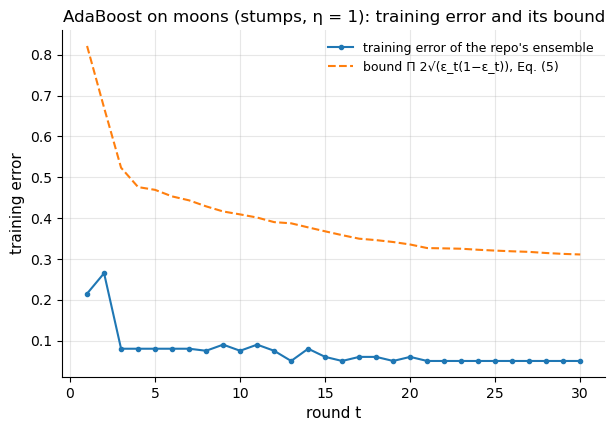

In [8]:
# Check — Eq. (3) for every round, and the training-error bound of Eq. (5) at every stage
assert np.allclose(alphas, 0.5 * np.log((1 - eps) / eps))
bound = np.cumprod(2 * np.sqrt(eps * (1 - eps)))
staged = ada_bin.get_staged_predictions(X_tr)
train_err = np.array([np.mean(np.array(p) != y_tr) for p in staged])
assert np.all(train_err <= bound + 1e-12)
print(f"✓ alpha_t = ½ ln((1-ε_t)/ε_t) for all {len(alphas)} rounds; training error ≤ Π 2√(ε(1-ε)) at every stage")

fig, ax = plt.subplots()
ax.plot(range(1, len(bound) + 1), train_err, "o-", ms=3, label="training error of the repo's ensemble")
ax.plot(range(1, len(bound) + 1), bound, "--", label="bound Π 2√(ε_t(1−ε_t)), Eq. (5)")
ax.set(title="AdaBoost on moons (stumps, η = 1): training error and its bound", xlabel="round t", ylabel="training error"); ax.legend()
plt.show()

Every stored $\alpha_t$ equals Eq. (3), and the training error stays under the bound of Eq. (5) at every stage. The bound itself decreases geometrically. It is loose (it bounds the exponential loss, not the error directly), but it explains why boosting drives the training error down so fast. Note that the individual errors $\varepsilon_t$ do *not* shrink over time: they hover below $\tfrac12$, because each new stump faces a harder, re-weighted problem.

### 4.3 Multiclass: SAMME, and why the repo's update is exactly SAMME

**Concept.** With $K > 2$ classes, "better than chance" means $\varepsilon < 1 - \frac1K$, not $\varepsilon < \frac12$. A three-class learner with 60% error still beats random guessing (67% error). **SAMME** (Zhu, Zou, Rosset & Hastie, 2009) generalises AdaBoost by adding a $\ln(K-1)$ term:

$$
\alpha_t^{\text{SAMME}} = \eta\Big(\ln\frac{1-\varepsilon_t}{\varepsilon_t} + \ln(K-1)\Big), \qquad w_i \leftarrow w_i\, \exp\big(\alpha_t^{\text{SAMME}}\,\mathbb{1}[h_t(x_i)\ne y_i]\big), \tag{6}
$$

followed by normalisation, and the prediction $\arg\max_k \sum_t \alpha_t^{\text{SAMME}}\mathbb{1}[h_t(x) = k]$. The $\ln(K-1)$ term makes $\alpha > 0$ exactly when the learner beats chance:

$$
\ln\frac{1-\varepsilon}{\varepsilon} + \ln(K-1) > 0 \iff (1-\varepsilon)(K-1) > \varepsilon \iff \varepsilon < \frac{K-1}{K} = 1 - \frac1K .
$$

SAMME is itself forward-stagewise minimisation of a multiclass exponential loss, which reduces to Eq. (3) when $K = 2$.

**Math: the repo is SAMME in disguise.** The repo uses $\alpha_t^{\text{code}} = \tfrac{\eta}{2}\big(\ln\frac{1-\varepsilon_t}{\varepsilon_t} + \ln(K-1)\big) = \tfrac12\alpha_t^{\text{SAMME}}$ and the *symmetric* update of Eq. (4): $\times e^{+\alpha}$ if wrong, $\times e^{-\alpha}$ if right. Write $e^{-\alpha}$ as a common factor:

$$
w_i\, e^{-\alpha^{\text{code}}}\, e^{2\alpha^{\text{code}}\mathbb{1}[\text{wrong}]} = \underbrace{e^{-\alpha^{\text{code}}}}_{\text{same for all } i}\, w_i\, e^{\alpha^{\text{SAMME}}\mathbb{1}[\text{wrong}]} .
$$

The common factor cancels in the normalisation, so the **normalised weights are identical to SAMME's**. Hence the same learners are trained. The vote uses $\alpha^{\text{code}} = \tfrac12\alpha^{\text{SAMME}}$, and multiplying every score by $\tfrac12$ does not change the argmax. So the predictions are identical too. (In the binary case, the code is literally Eqs. (3)–(4).)

**Illustration plus check.** An independent, textbook SAMME loop (illustration code), using the repo's weighted tree as the weak learner, run side by side with `AdaBoostClassifier` on a 3-class problem.

In [9]:
# Illustration only — textbook SAMME (Eq. 6), using the repo's WeightedTree as the weak learner
def samme(X, y, T, eta):
    K = len(np.unique(y)); w = np.full(len(y), 1 / len(y)); learners, alphas_s = [], []
    for _ in range(T):
        h = WeightedTree(max_depth=1); h.fit(X, y, w)
        miss = (np.array(h.predict(X)) != y).astype(float)
        e = np.clip(np.sum(w * miss) / w.sum(), 1e-10, 1 - 1e-10)
        if e >= 1 - 1 / K:
            break
        a = eta * (np.log((1 - e) / e) + np.log(K - 1))
        w = w * np.exp(a * miss); w = w / w.sum()                     # SAMME: only misclassified points change
        learners.append(h); alphas_s.append(a)
    return learners, np.array(alphas_s)

X3, y3 = make_blobs(240, centers=[[0, 0], [2.2, 0], [1.1, 1.9]], std=0.9)
X3_te, y3_te = make_blobs(1000, centers=[[0, 0], [2.2, 0], [1.1, 1.9]], std=0.9)
learners_s, alphas_s = samme(X3, y3, T=40, eta=0.5)
ada3 = AdaBoostClassifier(n_estimators=40, max_depth=1, learning_rate=0.5); ada3.fit(X3, y3)
print("SAMME alphas (first 5):      ", np.round(alphas_s[:5], 4))
print("repo alphas × 2 (first 5):   ", np.round(2 * np.array(ada3.alphas[:5]), 4))

SAMME alphas (first 5):       [0.6288 0.6083 0.5797 0.4314 0.5229]
repo alphas × 2 (first 5):    [0.6288 0.6083 0.5797 0.4314 0.5229]


In [10]:
# Check — same learners, alphas differing by exactly a factor 2, identical predictions
assert len(learners_s) == len(ada3.trees)
for h_s, h_r in zip(learners_s, ada3.trees):
    assert (h_s.root.feature_index, h_s.root.threshold) == (h_r.root.feature_index, h_r.root.threshold)
assert np.allclose(alphas_s, 2 * np.array(ada3.alphas))
scores = np.zeros((len(X3_te), 3))
for h, a in zip(learners_s, alphas_s):
    p = np.array(h.predict(X3_te)); scores[np.arange(len(p)), p.astype(int)] += a
assert np.array_equal(np.argmax(scores, axis=1).astype(float), np.array(ada3.predict(X3_te)))
print(f"✓ all {len(learners_s)} stumps identical, alpha_SAMME = 2·alpha_repo, identical predictions on {len(X3_te)} test points")
print(f"test accuracy {acc(ada3.predict(X3_te), y3_te):.3f}")

✓ all 40 stumps identical, alpha_SAMME = 2·alpha_repo, identical predictions on 1000 test points
test accuracy 0.826


The check confirms the algebra: the repo trains *the same sequence of stumps* as textbook SAMME, its $\alpha$'s are exactly half of SAMME's, and its predictions are identical.

> 🔧 **Fixed in the code — the documentation of the update.**
> *Originally:* the module docstring described plain SAMME, `alpha = learning_rate * (log((1-err)/err) + log(K-1))` with `w_i *= exp(alpha * I(miss))`, while the code used half that $\alpha$ and the symmetric $e^{\pm\alpha}$ update. As shown above, the two are equivalent, but the documentation did not match the code.
> *Now:* the docstring states the code's formulas and explains the equivalence.

### 4.4 Stopping rules

**Concept and math.** If a learner is no better than chance ($\varepsilon_t \ge 1 - 1/K$), its $\alpha_t$ would be $\le 0$, so it carries no useful information. At the other extreme, a **perfect** learner ($\varepsilon_t = 0$) makes Eq. (3) infinite. The code clips $\varepsilon$ to $[10^{-10}, 1 - 10^{-10}]$, which gives $\alpha \approx \tfrac{\eta}{2} \ln 10^{10} \approx 11.5\,\eta$ for a perfect learner. Moreover, a perfect learner multiplies *every* weight by $e^{-\alpha}$, which cancels in the normalisation. The weights do not change, so the next round would fit the very same tree.

> 🔧 **Fixed in the code — what happens at the extremes.**
> *Originally:* (1) A learner no better than chance stopped boosting with `break`, which is correct, but the comment said "skip this learner". (2) If the *first* learner already failed, the model kept no learners at all, and `predict` silently returned `classes_[0]` for every input, whatever the class frequencies. (3) After a perfect learner, every later round refit the same tree, wasting time and stacking the same vote $T$ times. (4) With a single class, $\ln(K-1) = \ln 0 = -\infty$ produced a non-finite $\alpha$. (5) `get_estimator_errors` was documented as returning weighted errors but returned unweighted ones.
> *Now:* the comment matches the `break`. If no learner is kept, `predict` returns the most frequent training class (`fallback_class_`). Boosting stops right after a perfect learner. A one-class training set is handled up front. The weighted errors used for $\alpha$ are stored in `estimator_errors_`, and `get_estimator_errors` is documented as the unweighted error on the data passed in. The tree no longer touches NumPy's global random state (it uses no randomness).

In [11]:
# (1)+(2): a data set where no stump beats chance -> no learners kept -> majority-class fallback
X_bad = np.array([[0.], [0.], [1.], [1.]]); y_bad = np.array([0., 1., 0., 1.])
a_bad = AdaBoostClassifier(n_estimators=10); a_bad.fit(X_bad, y_bad)
print(f"balanced, inseparable data: learners kept = {len(a_bad.trees)}, predict -> {a_bad.predict(X_bad)}")
y_bad2 = np.array([0., 1., 1., 1.]); X_bad2 = np.array([[0.], [0.], [0.], [0.]])
a_bad2 = AdaBoostClassifier(n_estimators=10); a_bad2.fit(X_bad2, y_bad2)
print(f"identical inputs, labels 0,1,1,1: learners kept = {len(a_bad2.trees)}, predict -> {a_bad2.predict(X_bad2[:1])} (majority class)")
# (3): a perfectly separable problem -> one perfect stump, then stop
a_sep = AdaBoostClassifier(n_estimators=50); a_sep.fit(x1d, (x1d.ravel() > 5).astype(float))
print(f"separable data: learners kept = {len(a_sep.trees)} (stopped after the perfect stump), alpha = {a_sep.alphas[0]:.2f}")
# (4): one class
a_one = AdaBoostClassifier(n_estimators=5); a_one.fit(x1d, np.ones(10))
print(f"one class: learners kept = {len(a_one.trees)}, predict -> {a_one.predict(x1d[:2])}")
assert len(a_sep.trees) == 1 and a_bad2.predict(X_bad2[:1]) == [1.0]

balanced, inseparable data: learners kept = 0, predict -> [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]
identical inputs, labels 0,1,1,1: learners kept = 1, predict -> [np.float64(1.0)] (majority class)
separable data: learners kept = 1 (stopped after the perfect stump), alpha = 11.51
one class: learners kept = 0, predict -> [np.float64(1.0), np.float64(1.0)]


On balanced, inseparable data no stump beats chance, so no learner is kept, and the model predicts the most frequent class (with a tie, the smallest label). When three of four identical inputs are labelled 1, it predicts 1. A perfectly separable problem stops after one perfect stump with $\alpha \approx 11.5$. A one-class training set simply predicts that class.

## 5. Implementation walkthrough, in the order the code runs

```
AdaBoostClassifier(n_estimators=50, max_depth=1, learning_rate=1.0, random_state=None)
  fit(X, Y):
     classes_, fallback_class_ (most frequent class);  K = number of classes   (K < 2: stop)
     w = 1/n for every sample
     for t in range(n_estimators):
         tree = WeightedTree(max_depth); tree.fit(X, Y, w)          # weighted Gini, §4.1
         miss = (tree.predict(X) != Y); ε = Σ w·miss / Σ w            # weighted error
         ε = clip(ε, 1e-10, 1-1e-10);  if ε ≥ 1 - 1/K: break          # no better than chance
         α = η · ½ · (ln((1-ε)/ε) + ln(K-1))                          # Eq. (3) / ½·Eq. (6)
         w *= exp(+α) on misclassified, exp(-α) on correct;  w /= Σ w  # Eq. (4)
         store tree, α, ε;   if raw ε == 0: break                      # perfect learner
  predict(X):  scores[:, k] += α_t · 1[h_t(x) = k]  → argmax          (fallback class if no trees)
```

**`AdaBoostClassifier.__init__` (AdaBoost.py, lines 43–58).** Validates `n_estimators ≥ 1` and `learning_rate > 0` and stores the hyperparameters. `random_state` is accepted for API compatibility but unused, since the algorithm is deterministic.

**`fit(X, Y)` (lines 60–130).** The loop above. `Y` may be 1-D or a column. The tree is refit from scratch every round with the current weights. `predictions == Y_flat` gives the correct/misclassified indicators. Note that the stored $\alpha$ uses the *clipped* error, while the perfect-learner test uses the raw one.

**`predict(X)` (lines 132–156).** Accumulates `alpha * (predictions == cls)` into a score matrix and returns the class with the largest score per row. **`get_staged_predictions(X)` (lines 158–176)** does the same while recording the prediction after every round (used for learning curves). **`get_estimator_weights()`** returns the $\alpha$ list; **`get_estimator_errors(X, Y)`** returns each learner's unweighted error on the given data.

**`DecisionTreeAdaBoost.DecisionTreeClassifier`.** `fit(X, Y, sample_weights=None)` validates its inputs (uniform weights if none are given; negative weights rejected). `build_tree` / `get_best_split` mirror the [classification tree](../DecisionTree/DecisionTree_Walkthrough.ipynb), but carry the weights along: `split` uses boolean masks to split the rows and the weights together, `information_gain` weights children by their share of the weight, and `gini_index` / `entropy` / `calculate_leaf_value` use weighted proportions (§4.1). A node carrying zero total weight is treated as pure, which avoids $0/0$. As in the fixed `DecisionTree.py`, a node with no valid split becomes a leaf and `max_depth=None` means unlimited.

**`Main.py`.** Fits this model to the Wine data and compares it with scikit-learn's `AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), learning_rate=0.25)`, which also uses the SAMME formula of Eq. (6). By §4.3 the two should choose the same stumps whenever their split searches agree. (scikit-learn uses midpoint thresholds, so in general they may differ slightly.) It needs scikit-learn and is not run here.

## 6. Worked numerical example: three rounds on ten points

Ten 1-D points, $x = 1, \dots, 10$, with labels $1, 1, 0, 0, 0, 1, 1, 1, 0, 0$: class 1 sits in two separate intervals. No single stump can get this right. Three can.

In [12]:
x_toy = np.arange(1, 11, dtype=float).reshape(-1, 1)
y_toy = np.array([1, 1, 0, 0, 0, 1, 1, 1, 0, 0], dtype=float)
toy = AdaBoostClassifier(n_estimators=3, max_depth=1, learning_rate=1.0)
toy.fit(x_toy, y_toy)

# Replay the round-by-round weights with Eq. (4) (illustration), and check them against the repo's stored ε and α
w = np.full(10, 0.1); scores = np.zeros((10, 2))
for t, (tree, a, e) in enumerate(zip(toy.trees, toy.alphas, toy.estimator_errors_)):
    pred = np.array(tree.predict(x_toy)); miss = pred != y_toy
    print(f"--- round {t + 1}: weights before = {np.round(w, 4)}")
    print(f"    stump: x_0 <= {tree.root.threshold}  -> left {tree.root.left.value:.0f}, right {tree.root.right.value:.0f};  "
          f"misclassified points: x = {x_toy[miss].ravel().astype(int).tolist()}")
    eps_t = w[miss].sum()
    print(f"    ε = {eps_t:.4f} (repo: {e:.4f});  α = ½ ln((1-ε)/ε) = {0.5 * np.log((1 - eps_t) / eps_t):.4f} (repo: {a:.4f})")
    assert np.isclose(eps_t, e) and np.isclose(a, 0.5 * np.log((1 - eps_t) / eps_t))
    w = w * np.where(miss, np.exp(a), np.exp(-a)); w = w / w.sum()
    scores[np.arange(10), pred.astype(int)] += a
    print(f"    ensemble scores (class0, class1) per point: {np.round(scores, 3).tolist()}")
    print(f"    ensemble prediction: {np.argmax(scores, axis=1).tolist()}  training accuracy {np.mean(np.argmax(scores, axis=1) == y_toy):.1f}")
print("\nrepo predict():", np.array(toy.predict(x_toy)).astype(int).tolist(), " true labels:", y_toy.astype(int).tolist())
assert np.array_equal(np.array(toy.predict(x_toy)), y_toy)

--- round 1: weights before = [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
    stump: x_0 <= 2.0  -> left 1, right 0;  misclassified points: x = [6, 7, 8]
    ε = 0.3000 (repo: 0.3000);  α = ½ ln((1-ε)/ε) = 0.4236 (repo: 0.4236)
    ensemble scores (class0, class1) per point: [[0.0, 0.424], [0.0, 0.424], [0.424, 0.0], [0.424, 0.0], [0.424, 0.0], [0.424, 0.0], [0.424, 0.0], [0.424, 0.0], [0.424, 0.0], [0.424, 0.0]]
    ensemble prediction: [1, 1, 0, 0, 0, 0, 0, 0, 0, 0]  training accuracy 0.7
--- round 2: weights before = [0.0714 0.0714 0.0714 0.0714 0.0714 0.1667 0.1667 0.1667 0.0714 0.0714]
    stump: x_0 <= 8.0  -> left 1, right 0;  misclassified points: x = [3, 4, 5]
    ε = 0.2143 (repo: 0.2143);  α = ½ ln((1-ε)/ε) = 0.6496 (repo: 0.6496)
    ensemble scores (class0, class1) per point: [[0.0, 1.073], [0.0, 1.073], [0.424, 0.65], [0.424, 0.65], [0.424, 0.65], [0.424, 0.65], [0.424, 0.65], [0.424, 0.65], [1.073, 0.0], [1.073, 0.0]]
    ensemble prediction: [1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

Reading the three rounds:
- **Round 1.** With uniform weights, the best stump is $x_0 \le 2$ (class 1 on the left), which misses the middle group $x = 6, 7, 8$: $\varepsilon = 0.3$ and $\alpha = \tfrac12\ln\tfrac{0.7}{0.3} = 0.424$. By Eq. (4), the three missed points are multiplied by $e^{0.424}$ and the rest by $e^{-0.424}$. After normalising, the missed points each carry $1/6$ and the others $1/14$. Exactly half the total weight now sits on the mistakes. This always happens: after the update, the learner just used has weighted error exactly $\tfrac12$ on the new weights, so the next learner cannot simply repeat it.
- **Round 2.** The heavy points 6–8 pull the next stump to $x_0 \le 8$, which labels them correctly at the cost of $x = 3, 4, 5$ ($\varepsilon = 3/14 = 0.214$, $\alpha = 0.650$). The combined vote now predicts class 1 for everything up to 8: accuracy is still 0.7, but with different mistakes.
- **Round 3.** Points 3–5 are now the heaviest, and the stump $x_0 \le 5$ (class 1 on the *right*) fixes them while missing 1, 2, 9 and 10 ($\varepsilon = 0.182$, $\alpha = 0.752$). Summing the three weighted votes yields class 1 exactly on $\{1, 2\} \cup \{6, 7, 8\}$, so training accuracy is 1.0.

The printed $\varepsilon$ and $\alpha$ match the values stored by the repo (`estimator_errors_`, `alphas`) in every round, and `predict` reproduces the final labels.

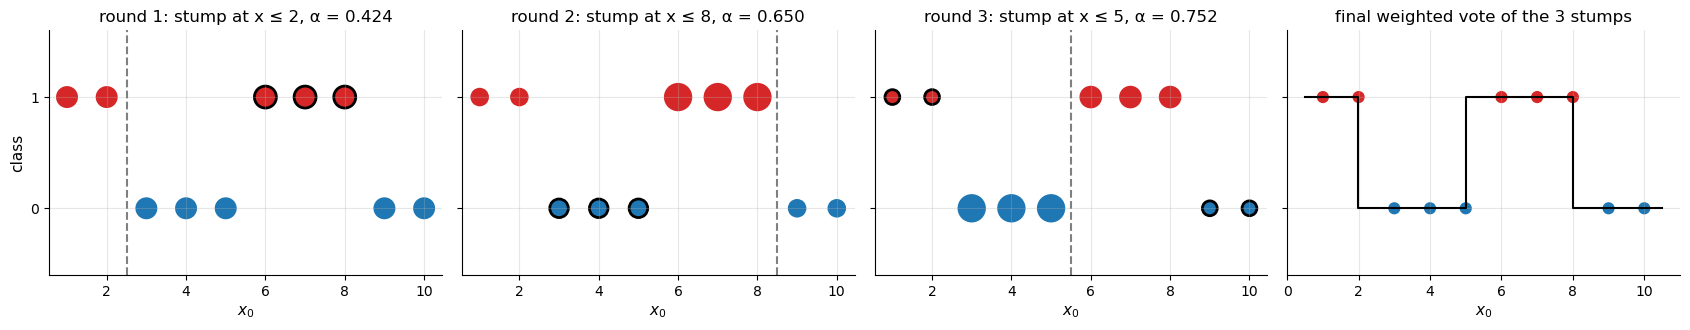

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
w = np.full(10, 0.1)
for t in range(3):
    tree, a = toy.trees[t], toy.alphas[t]
    pred = np.array(tree.predict(x_toy)); miss = pred != y_toy
    ax = axes[t]
    ax.scatter(x_toy.ravel(), y_toy, s=2500 * w, c=[CLASS_COLORS[int(k)] for k in y_toy], edgecolor=np.where(miss, "k", "none"), linewidth=2)
    ax.axvline(tree.root.threshold + 0.5, color="gray", ls="--")
    ax.set(title=f"round {t + 1}: stump at x ≤ {tree.root.threshold:.0f}, α = {a:.3f}", xlabel="$x_0$", yticks=[0, 1], ylim=(-0.6, 1.6))
    w = w * np.where(miss, np.exp(a), np.exp(-a)); w = w / w.sum()
axes[0].set_ylabel("class")
xx = np.linspace(0.5, 10.5, 400).reshape(-1, 1)
axes[3].step(xx.ravel(), toy.predict(xx), where="mid", color="k")
axes[3].scatter(x_toy.ravel(), y_toy, c=[CLASS_COLORS[int(k)] for k in y_toy], s=60)
axes[3].set(title="final weighted vote of the 3 stumps", xlabel="$x_0$")
plt.tight_layout(); plt.show()

Marker area is proportional to the weight a point carries **when that round's stump is trained**, and black rings mark the points that stump gets wrong. The weight visibly flows onto the points the previous stumps missed. The last panel is the final vote, a two-interval rule that none of the three stumps could express alone.

## 7. Visual experiments

### 7.1 The decision boundary as stumps are added

stumps kept: 200


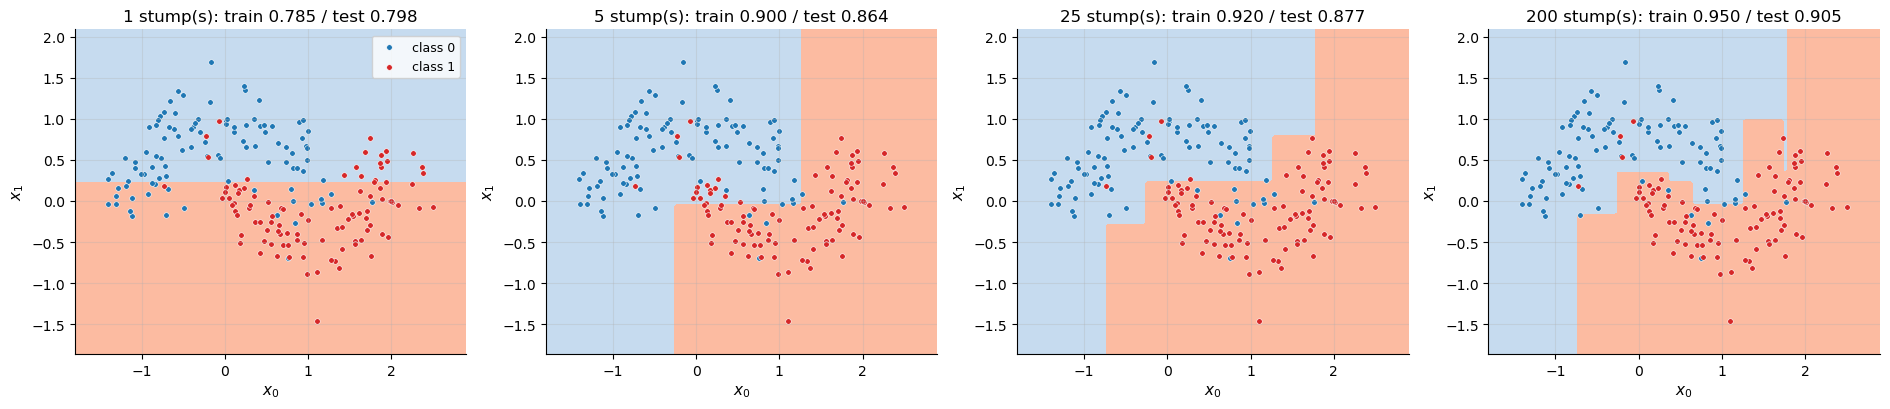

In [14]:
ada = AdaBoostClassifier(n_estimators=200, max_depth=1, learning_rate=0.5)
ada.fit(X_tr, y_tr)
print(f"stumps kept: {len(ada.trees)}")

class FirstT:                                            # Illustration only: wrap the first T stumps of a fitted model
    def __init__(self, model, T): self.m, self.T = model, T
    def predict(self, X):
        scores = np.zeros((len(X), len(self.m.classes_)))
        for tree, a in zip(self.m.trees[:self.T], self.m.alphas[:self.T]):
            p = np.array(tree.predict(X))
            for j, c in enumerate(self.m.classes_):
                scores[:, j] += a * (p == c)
        return self.m.classes_[np.argmax(scores, axis=1)]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, T in zip(axes, [1, 5, 25, 200]):
    sub = FirstT(ada, T)
    plot_decision_regions(sub.predict, X_tr, y_tr, ax=ax, grid_n=100, legend=(T == 1),
                          title=f"{T} stump(s): train {acc(sub.predict(X_tr), y_tr):.3f} / test {acc(sub.predict(X_te), y_te):.3f}")
assert np.array_equal(FirstT(ada, len(ada.trees)).predict(X_te), np.array(ada.predict(X_te)))   # wrapper == repo at T_max
plt.tight_layout(); plt.show()

One stump is a single straight cut. Five stumps already form a staircase that bends around the moons. With more rounds, the staircase follows the curved boundary more closely, and both training and test accuracy rise. Every stump is a cut across the *whole* plane, so the boundary is a sum of full-width or full-height steps and stays coarse and blocky, unlike the small local boxes of a deep tree. The final assertion confirms that the wrapper, which uses only the first $T$ stored stumps, reproduces the repo's `predict` when all of them are used.

### 7.2 Learning curves: training and test error by round

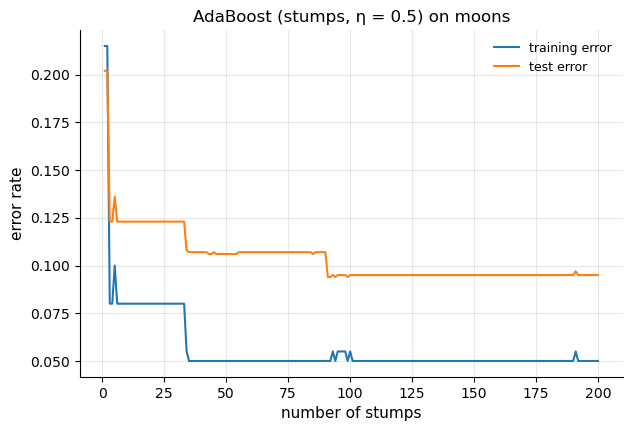

after 1 stump: train 0.215 / test 0.202;  best test 0.094 at round 91;  after 200: train 0.050 / test 0.095


In [15]:
def staged_errors(model, X, y):
    return np.array([np.mean(np.array(p) != y) for p in model.get_staged_predictions(X)])

tr_err, te_err = staged_errors(ada, X_tr, y_tr), staged_errors(ada, X_te, y_te)
fig, ax = plt.subplots()
ax.plot(range(1, len(tr_err) + 1), tr_err, label="training error")
ax.plot(range(1, len(te_err) + 1), te_err, label="test error")
ax.set(title="AdaBoost (stumps, η = 0.5) on moons", xlabel="number of stumps", ylabel="error rate"); ax.legend(); plt.show()
print(f"after 1 stump: train {tr_err[0]:.3f} / test {te_err[0]:.3f};  best test {te_err.min():.3f} at round {te_err.argmin() + 1};"
      f"  after {len(te_err)}: train {tr_err[-1]:.3f} / test {te_err[-1]:.3f}")

Training error falls quickly over the first few stumps, then keeps creeping down. Test error drops from about 0.20 with one stump to below 0.10, and then stays essentially flat for the remaining rounds, with no marked rise even after 200 stumps. Boosting's resistance to overfitting with weak learners is a well-known empirical observation. The *margin* explanation is that later rounds keep increasing the margins $y_iF(x_i)$ of the training points even after the training error stops changing, which tends to help generalisation. With noisy labels and strong learners, boosting *does* overfit (§7.3–7.4).

### 7.3 Learning rate and weak-learner depth

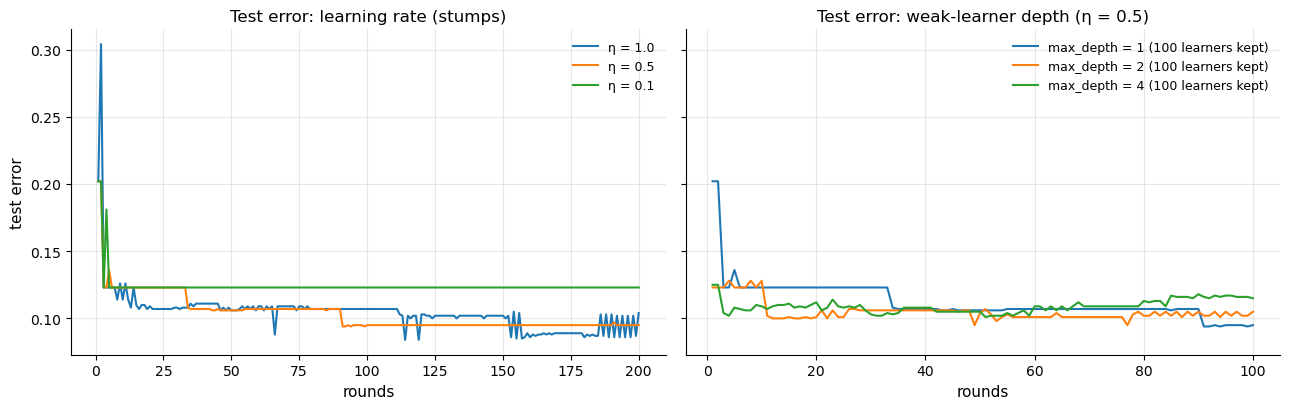

η = 1.0: test error after 10 rounds 0.114, after 200 rounds 0.104, best 0.084
η = 0.5: test error after 10 rounds 0.123, after 200 rounds 0.095, best 0.094
η = 0.1: test error after 10 rounds 0.123, after 200 rounds 0.123, best 0.123
max_depth = 1: learners kept 100, final train error 0.055, final test error 0.095, best 0.094
max_depth = 2: learners kept 100, final train error 0.040, final test error 0.105, best 0.095
max_depth = 4: learners kept 100, final train error 0.000, final test error 0.115, best 0.101


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
results_lr = {}
for eta in [1.0, 0.5, 0.1]:
    m_ = AdaBoostClassifier(n_estimators=200, max_depth=1, learning_rate=eta); m_.fit(X_tr, y_tr)
    e_ = staged_errors(m_, X_te, y_te); results_lr[eta] = e_
    axes[0].plot(range(1, len(e_) + 1), e_, label=f"η = {eta}")
axes[0].set(title="Test error: learning rate (stumps)", xlabel="rounds", ylabel="test error"); axes[0].legend()
results_depth = {}
for depth in [1, 2, 4]:
    m_ = AdaBoostClassifier(n_estimators=100, max_depth=depth, learning_rate=0.5); m_.fit(X_tr, y_tr)
    e_ = staged_errors(m_, X_te, y_te); results_depth[depth] = (e_, len(m_.trees), staged_errors(m_, X_tr, y_tr)[-1])
    axes[1].plot(range(1, len(e_) + 1), e_, label=f"max_depth = {depth} ({len(m_.trees)} learners kept)")
axes[1].set(title="Test error: weak-learner depth (η = 0.5)", xlabel="rounds"); axes[1].legend()
plt.tight_layout(); plt.show()
for eta, e_ in results_lr.items():
    print(f"η = {eta}: test error after 10 rounds {e_[min(9, len(e_)-1)]:.3f}, after {len(e_)} rounds {e_[-1]:.3f}, best {e_.min():.3f}")
for d, (e_, kept, tr_last) in results_depth.items():
    print(f"max_depth = {d}: learners kept {kept}, final train error {tr_last:.3f}, final test error {e_[-1]:.3f}, best {e_.min():.3f}")

**Learning rate (left).** With $\eta = 1$ the error drops fastest and reaches the lowest point of the three, but late in the run it oscillates. Each new stump moves the score a lot, and points near the boundary flip back and forth. $\eta = 0.5$ descends in fewer, steadier steps. $\eta = 0.1$ is so cautious that, within 200 rounds, the weights change too slowly for new stumps to emerge, and its error is still stuck at the early plateau. Smaller learning rates need proportionally more rounds; in exchange they usually give smoother, more stable ensembles.

**Weak-learner depth (right).** Deeper learners are individually stronger, so the training error falls faster: depth-4 trees drive it to zero. But the test error does not improve, and ends higher for depth 4 than for stumps. The extra capacity is spent fitting the noise in the overlap region. Shallow learners are the classic choice for AdaBoost for this reason.

### 7.4 Sensitivity to label noise

AdaBoost's weights are $w_i \propto e^{-y_i F(x_i)}$ (§4.2). A point that the ensemble keeps getting wrong has a large negative margin, and its weight grows *exponentially*. If that point is **mislabelled**, the algorithm pours more and more effort into fitting noise. We flip 10% of the training labels and track what share of the total weight sits on the flipped points.

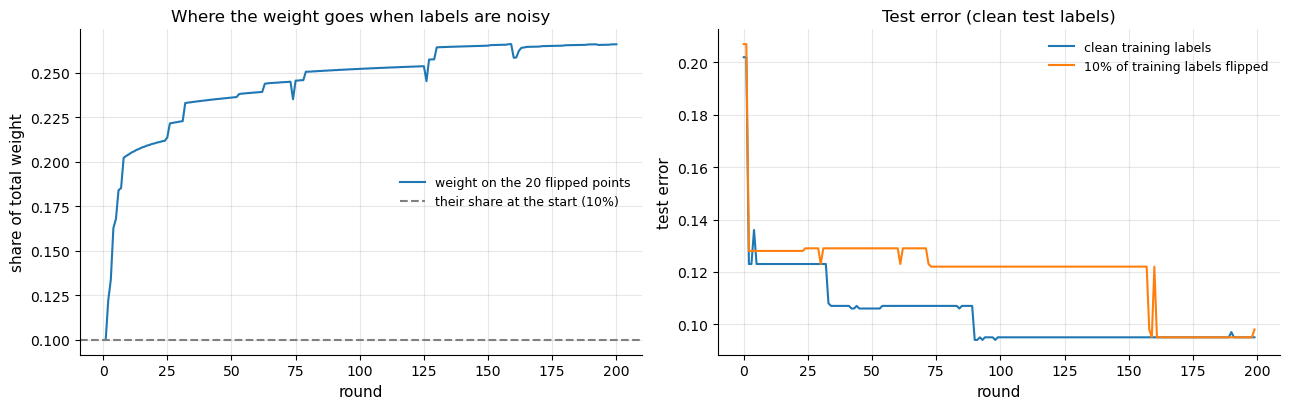

weight share on flipped points: round 1 0.10, round 50 0.24, round 200 0.27
final test error: clean 0.095, noisy 0.098


In [17]:
y_noisy = y_tr.copy()
flipped = rng.choice(len(y_tr), size=20, replace=False); y_noisy[flipped] = 1 - y_noisy[flipped]
ada_n = AdaBoostClassifier(n_estimators=200, max_depth=1, learning_rate=0.5); ada_n.fit(X_tr, y_noisy)

# Illustration only — the weights before each round, replayed with Eq. (4) from the repo's stored stumps and alphas
w = np.full(len(y_noisy), 1 / len(y_noisy)); share = []
for tree, a in zip(ada_n.trees, ada_n.alphas):
    share.append(w[flipped].sum())
    miss = np.array(tree.predict(X_tr)) != y_noisy
    w = w * np.where(miss, np.exp(a), np.exp(-a)); w /= w.sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(range(1, len(share) + 1), share, label="weight on the 20 flipped points")
axes[0].axhline(20 / 200, color="gray", ls="--", label="their share at the start (10%)")
axes[0].set(title="Where the weight goes when labels are noisy", xlabel="round", ylabel="share of total weight"); axes[0].legend()
e_clean, e_noisy = staged_errors(ada, X_te, y_te), staged_errors(ada_n, X_te, y_te)
axes[1].plot(e_clean, label="clean training labels"); axes[1].plot(e_noisy, label="10% of training labels flipped")
axes[1].set(title="Test error (clean test labels)", xlabel="round", ylabel="test error"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"weight share on flipped points: round 1 {share[0]:.2f}, round 50 {share[49]:.2f}, round {len(share)} {share[-1]:.2f}")
print(f"final test error: clean {e_clean[-1]:.3f}, noisy {e_noisy[-1]:.3f}")

The share of the total weight carried by the 20 flipped points grows from their initial 10% to more than a quarter. The algorithm keeps up-weighting points it cannot fit, as $w_i \propto e^{-y_iF(x_i)}$ predicts. In this run the damage to test accuracy is limited. The noisy model is worse than the clean one over the middle stretch of rounds, and the two end at a similar error, because stumps are too coarse to isolate individual mislabelled points. With more flexible learners, more noise, or more rounds, this concentration is what makes AdaBoost overfit noisy data. It motivates losses that grow more gently for badly misclassified points, such as the log-loss used by [gradient boosting](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb).

## 8. Hyperparameters

| Hyperparameter | What it controls | Effect |
|---|---|---|
| `n_estimators` ($T$) | maximum number of rounds | More rounds lower the training error (Eq. 5); test error usually plateaus but can rise with noisy labels. Boosting may stop earlier (§4.4). |
| `learning_rate` ($\eta$) | multiplies every $\alpha_t$ | Smaller $\eta$ means smaller steps: slower progress per round, often a slightly better and smoother final model, but more rounds needed (§7.3). |
| `max_depth` | complexity of each weak learner | Stumps (1) give a low-variance additive model; deeper trees make each learner stronger, which reduces the number of rounds needed but raises the risk of overfitting. Very deep learners can fit the weighted data perfectly, which stops boosting early (§4.4). |
| `random_state` | (unused) | AdaBoost with these trees is deterministic. |

## 9. Complexity and limitations

**Training.** $T$ rounds, each fitting one weighted tree of depth $D$. The tree uses vectorised mask splits, so one candidate costs $O(n)$ NumPy work, and a node costs $O(m\,n_{\text{node}}^2)$ with this exhaustive search. The total is $O(T\,D\,m\,n^2)$. **The rounds are inherently sequential**: round $t$ needs the weights produced by round $t-1$. **Prediction:** $O(T \cdot D)$ per point. **Memory:** $T$ small trees.

| Limitation | Consequence | What production libraries do |
|---|---|---|
| Exponential loss | weights explode on mislabelled points (§7.4) | robust variants (LogitBoost, gradient boosting with log-loss; see the [next notebooks](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb)) |
| No `predict_proba` | scores are not calibrated probabilities | scikit-learn offers `predict_proba` from the normalised scores |
| No early stopping on validation data | must pick $T$ by hand | `staged_predict` with a validation set; gradient boosting's `n_iter_no_change` |
| $O(m n^2)$ split search per node | slow for large $n$ | histogram / sorted-sweep split search |

Bugs found during this walkthrough and **fixed in the code**:

| Original behaviour | Fix |
|---|---|
| Docstring formula did not match the code's ½·α and symmetric update | docstring corrected; equivalence explained (§4.3) |
| No learner kept → `predict` silently returned `classes_[0]` | most-frequent-class fallback (§4.4) |
| Perfect learner refit identically for every remaining round | boosting stops after a perfect learner (§4.4) |
| One-class data → $\ln 0$ in $\alpha$ | handled before boosting (§4.4) |
| Comment "skip this learner" on a `break`; `get_estimator_errors` documented as weighted | comments fixed; weighted errors stored in `estimator_errors_` (§4.4) |
| Tree: empty `best_split` → `KeyError`; zero-weight nodes → $0/0$; global `np.random.seed` calls; `!= None` | leaf on no valid split; zero-weight guard; no global seeding; `is not None`; input validation |

## 10. Summary

- **Boosting** combines weak learners *sequentially*. Each round re-weights the training data toward the current mistakes, and the final model is a weighted vote: an additive model that mainly reduces **bias**.
- AdaBoost is greedy minimisation of the **exponential loss** $\sum_i e^{-y_iF(x_i)}$ (Eq. 1). The sample weights are $e^{-y_iF(x_i)}$; the best learner minimises weighted error; its weight is $\alpha = \frac12\ln\frac{1-\varepsilon}{\varepsilon}$ (Eq. 3); the update is $\times e^{\pm\alpha}$ (Eq. 4); and training error is bounded by $\prod_t 2\sqrt{\varepsilon_t(1-\varepsilon_t)}$ (Eq. 5). All of these were checked against the repo's stored $\varepsilon_t$, $\alpha_t$ and staged predictions.
- For $K$ classes, **SAMME** adds $\ln(K-1)$ so that "better than chance" means $\varepsilon < 1 - 1/K$ (Eq. 6). The repo's symmetric update with half-size $\alpha$ is algebraically identical to SAMME: same learners, same predictions. This was confirmed against an independent SAMME loop.
- The weak learner is a CART tree with **weighted** Gini, gain and majority (§4.1); re-weighting changes which split is best.
- Experiments: stumps combine into a staircase boundary; training error falls fast; smaller learning rates need more rounds; and label noise pulls a growing share of the weight onto mislabelled points.
- Fixed during this walkthrough: the mismatched docstring, the silent `classes_[0]` fallback, repeated perfect learners, the one-class $\ln 0$, misleading comments, and the tree's `KeyError` / zero-weight / global-seeding issues.

**Next:** generalising boosting from the exponential loss to *any* differentiable loss: [Gradient Boosting for regression](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb).